# 🎲 Incertitude et sensibilité de la simulation 2026-2027

**Groupe :** Maxime, Loan, Moussa, Mouhamedou et Ousmane — partie incertitude : Loan

## Pourquoi ce notebook ?
`SIMULATION_2026.ipynb` (Maxime) donne par exemple **23,3 % de titre à Arsenal**, avec une marge de ± 0,8 point. Mais cette marge ne mesure qu'une chose : le **hasard de la simulation** (10 000 saisons, pas une infinité). Elle fait comme si les coefficients du modèle étaient **connus exactement**.

Or ces coefficients sont **estimés** sur 1 871 matchs : ils ont eux-mêmes une marge d'erreur (leurs intervalles de confiance dans `MODEL_POISSON`). Ce notebook répond à deux questions :
1. **Intervalles :** si on tient compte de l'incertitude sur les coefficients, quelle est la vraie fourchette des probabilités de titre ?
2. **Sensibilité :** le classement des favoris change-t-il si on modifie l'avantage du terrain ou le poids de l'Elo ?

## Règles
- **On ne modifie ni le modèle ni la simulation.** Le moteur de Maxime est **lu directement** dans `SIMULATION_2026.ipynb` et exécuté tel quel. On vérifie qu'on retrouve exactement ses chiffres avant de faire quoi que ce soit.
- **Aucune donnée nouvelle**, et des graines fixes : les résultats sont reproductibles.

## Plan
1. Charger le moteur de Maxime et retrouver ses chiffres
2. L'incertitude des coefficients du modèle
3. Intervalles sur les probabilités de titre
4. Analyse de sensibilité : terrain et poids de l'Elo
5. Export
6. Conclusion

In [1]:
from pathlib import Path
from collections import Counter
from math import factorial
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from joblib import Parallel, delayed
import statsmodels.api as sm

%config InlineBackend.figure_format = 'retina'
BLEU, ORANGE, GRIS, ENCRE = '#2a78d6', '#eb6834', '#b5b3ad', '#52514e'
GRAINE = 2026                 # même graine que SIMULATION_2026
N_TIRAGES = 100               # jeux de coefficients tirés au hasard
N_SAISONS_PAR_TIRAGE = 2_000  # saisons simulées pour chaque jeu de coefficients
N_SENSIBILITE = 10_000        # saisons par scénario de sensibilité
COEFS = ['intercept', 'coef_ecart_100', 'coef_terrain', 'coef_nouveau_format']

# Le moteur de Maxime : on exécute ses cellules de définitions, sans les recopier ni les modifier
source = json.loads(Path('SIMULATION_2026.ipynb').read_text(encoding='utf-8'))
fonctions = ['def buts_attendus(', 'def preparer_calendrier(', 'def actualiser_elo(', 'def classer_ligue(', 'def campagne_simulation(']
cellules = [''.join(c['source']) for c in source['cells'] if c['cell_type'] == 'code'
            and any(f in ''.join(c['source']) for f in fonctions)]
assert len(cellules) == len(fonctions), "Le notebook de Maxime a changé : vérifier les cellules chargées"
for c in cellules:
    exec(c)
assert all(callable(globals()[n]) for n in ['simuler_saison', 'campagne_simulation', 'preparer_calendrier', 'tirer_score'])

# Les mêmes entrées que SIMULATION_2026
p = joblib.load('../output/modele_scores.joblib')           # notre fichier, produit par MODEL_POISSON
calendrier = pd.read_csv('../output/calendrier_2026.csv', parse_dates=['date'], encoding='utf-8-sig')
elos = pd.read_csv('../output/elo_participants_2026.csv', encoding='utf-8-sig')
clubs = calendrier[['club_id', 'nom_uefa']].drop_duplicates().sort_values('club_id').reset_index(drop=True)
elo_initial = clubs['club_id'].map(elos.set_index('club_id')['elo_complet']).to_numpy(float)
cal_2026 = preparer_calendrier(calendrier.loc[calendrier['lieu'].eq('domicile')], clubs)
assert len(clubs) == 36 and np.isfinite(elo_initial).all()
print(f"Moteur chargé : {len(cellules)} cellules de SIMULATION_2026 | {len(cal_2026['affiches'])} matchs | 36 clubs")
print("Coefficients du modèle :", {k: round(p[k], 4) for k in COEFS})

Moteur chargé : 5 cellules de SIMULATION_2026 | 144 matchs | 36 clubs
Coefficients du modèle : {'intercept': 0.3181, 'coef_ecart_100': 0.1996, 'coef_terrain': 0.1283, 'coef_nouveau_format': 0.1331}


## 1. Retrouver les chiffres de Maxime

**Pourquoi :** si notre copie du moteur ne donnait pas exactement les mêmes résultats, tout ce qui suit serait faux. On relance donc sa simulation de référence (10 000 saisons, graine 2026) et on compare :
- aux chiffres publiés par Maxime dans `README_SIMULATION.md` (Arsenal 23,30 %, Man City 14,96 %, Bayern 12,40 %, Barcelone 11,46 %), toujours disponibles dans le dépôt ;
- et, s'il existe, à son fichier complet `output/resultats_simulation_2026.csv`, pour les 36 clubs.

In [2]:
debut = time.perf_counter()
reference = campagne_simulation(cal_2026, clubs, elo_initial, p, 10_000, np.random.default_rng(GRAINE), progression=False)['resultats']
pct_ref = (100 * reference.set_index('nom_uefa')['p_titre']).round(2)

# 1. Les chiffres publiés dans README_SIMULATION.md
publies = {'Arsenal': 23.30, 'Man City': 14.96, 'Bayern München': 12.40, 'FC Barcelona': 11.46}
assert all(pct_ref[club] == valeur for club, valeur in publies.items()), "On ne retrouve pas les chiffres publiés par Maxime"

# 2. Son fichier complet, s'il a été régénéré en local
chemin_maxime = Path('../output/resultats_simulation_2026.csv')
if chemin_maxime.is_file():
    ref_maxime = pd.read_csv(chemin_maxime, encoding='utf-8-sig')
    comparaison = reference[['club_id', 'p_titre']].merge(ref_maxime[['club_id', 'p_titre']], on='club_id', suffixes=('', '_maxime'))
    assert len(comparaison) == 36 and np.allclose(comparaison['p_titre'], comparaison['p_titre_maxime'], atol=1e-12)
    print("Les 36 probabilités de titre de resultats_simulation_2026.csv sont retrouvées à l'identique.")
print(f"Chiffres publiés par Maxime retrouvés ({time.perf_counter() - debut:.0f} s) :")
print(pct_ref.sort_values(ascending=False).head(5).to_string())

Les 36 probabilités de titre de resultats_simulation_2026.csv sont retrouvées à l'identique.
Chiffres publiés par Maxime retrouvés (63 s) :
nom_uefa
Arsenal           23.30
Man City          14.96
Bayern München    12.40
FC Barcelona      11.46
Inter              8.01


**Lecture :** notre copie du moteur retrouve **exactement** la simulation de Maxime : Arsenal **23,30 %**, Man City **14,96 %**, Bayern **12,40 %**, Barcelone **11,46 %**, et les 36 probabilités de son fichier à l'identique. Tout ce qui suit repose donc sur le même moteur, les mêmes entrées et la même graine. Seuls les coefficients changent.

## 2. L'incertitude des coefficients du modèle

Le modèle a 4 coefficients (constante, Elo, terrain, nouveau format). Ils sont **estimés**, donc incertains. statsmodels donne leur **matrice de covariance** : la taille de l'incertitude de chacun, et la façon dont ils varient ensemble (si la constante est un peu plus haute, le format est souvent un peu plus bas, par exemple).

**La méthode :** on réentraîne exactement le modèle final de `MODEL_POISSON` (mêmes données, mêmes variables) avec statsmodels, et on vérifie qu'on retrouve les coefficients du fichier `modele_scores.joblib`. Puis on tire au hasard **100 jeux de coefficients** dans une loi normale centrée sur les coefficients estimés, avec cette covariance. Chaque jeu est un « modèle plausible » compte tenu des données.

In [3]:
g = pd.read_csv('../output/eda_matchs_c1.csv', encoding='utf-8-sig')
domicile = (~g['neutre'].astype(bool)).astype(int).to_numpy()
ecart = g['ecart_elo_complet'].to_numpy() / 100
nouveau = (g['season'] >= 2024).astype(int).to_numpy()
lignes = pd.DataFrame({                                      # 2 lignes par match, comme dans MODEL_POISSON
    'buts': np.r_[g['dom_j_buts_pour'], g['ext_j_buts_pour']],
    'ecart_100': np.r_[ecart, -ecart], 'terrain': np.r_[domicile, -domicile], 'nouveau_format': np.r_[nouveau, nouveau]})
ajust = sm.GLM(lignes['buts'], sm.add_constant(lignes[['ecart_100', 'terrain', 'nouveau_format']]), family=sm.families.Poisson()).fit()

estimes = ajust.params.to_numpy()
covariance = ajust.cov_params().to_numpy()
assert np.allclose(estimes, [p[k] for k in COEFS], atol=1e-4), "Ce n'est pas le modèle de modele_scores.joblib"

rng_coefs = np.random.default_rng(GRAINE)
tirages_coefs = rng_coefs.multivariate_normal(estimes, covariance, size=N_TIRAGES)
tableau_coefs = pd.DataFrame({
    'estimé': estimes, 'écart-type': np.sqrt(np.diag(covariance)),
    'IC 95 % bas': ajust.conf_int()[0].to_numpy(), 'IC 95 % haut': ajust.conf_int()[1].to_numpy(),
    'tirages : min': tirages_coefs.min(axis=0), 'tirages : max': tirages_coefs.max(axis=0)}, index=COEFS)
print(f"Modèle de modele_scores.joblib retrouvé. {N_TIRAGES} jeux de coefficients tirés.\n")
print(tableau_coefs.round(4).to_string())

Modèle de modele_scores.joblib retrouvé. 100 jeux de coefficients tirés.

                     estimé  écart-type  IC 95 % bas  IC 95 % haut  tirages : min  tirages : max
intercept            0.3181      0.0159       0.2869        0.3494         0.2800         0.3591
coef_ecart_100       0.1996      0.0070       0.1859        0.2133         0.1784         0.2158
coef_terrain         0.1283      0.0134       0.1021        0.1546         0.0867         0.1622
coef_nouveau_format  0.1331      0.0318       0.0708        0.1954         0.0163         0.2217


**Lecture :**
- **On retrouve le modèle de `modele_scores.joblib`** : constante 0,318, Elo 0,200, terrain 0,128, nouveau format 0,133.
- **Le coefficient le plus incertain est celui du nouveau format** : écart-type de 0,032, soit **24 %** de sa valeur (intervalle de 0,071 à 0,195). Celui de l'Elo est très précis : 0,007, soit **3,5 %**. C'est cohérent avec l'audit : le nouveau format n'a été observé que sur 2 saisons.
- **Les 100 tirages couvrent bien ces intervalles** : par exemple, le coefficient du format va de 0,016 à 0,222 selon le tirage.

## 3. Intervalles sur les probabilités de titre

**La méthode :** pour chacun des 100 jeux de coefficients, on simule **2 000 saisons** avec le moteur de Maxime, soit **200 000 saisons** en tout, réparties sur les cœurs du processeur. On obtient 100 probabilités de titre par club. Leur dispersion mélange deux sources d'incertitude :
- le **hasard de nos blocs de simulation** (2 000 saisons par jeu de coefficients) ;
- l'**incertitude des coefficients**, celle qui nous intéresse.

**On sépare les deux.** La variance due au hasard d'un bloc se calcule exactement : p × (1 − p) / 2 000. On la retire de la variance observée, et ce qui reste est la part due aux coefficients.

**Pourquoi ne pas prendre directement la fourchette des 100 valeurs ?** Parce qu'elle contiendrait le hasard de *nos* blocs de 2 000 saisons, plus bruités que la simulation de Maxime (10 000 saisons) : elle surestimerait l'incertitude. La bonne marge, pour la probabilité publiée par Maxime, additionne les deux variances :

$$\text{marge totale} = 1{,}96 \times \sqrt{\underbrace{\tfrac{p(1-p)}{10\,000}}_{\text{hasard de la simulation}} + \underbrace{\sigma^2_{\text{coefficients}}}_{\text{incertitude du modèle}}}$$

In [4]:
def simuler_avec(coefs, n, graine):
    # Une campagne de n saisons avec d'autres coefficients ; chaque bloc a sa propre graine fixe
    p_k = dict(p, **coefs)
    r = campagne_simulation(cal_2026, clubs, elo_initial, p_k, n, np.random.default_rng(graine), progression=False)['resultats']
    return r['p_titre'].to_numpy(), r['p_quarts'].to_numpy()

# Les 100 jeux de coefficients sont indépendants : on les répartit sur les cœurs du processeur.
# Graine [GRAINE, k] pour le jeu k : le résultat ne dépend pas du nombre de cœurs.
debut = time.perf_counter()
blocs = Parallel(n_jobs=-1)(delayed(simuler_avec)(dict(zip(COEFS, t)), N_SAISONS_PAR_TIRAGE, [GRAINE, k])
                            for k, t in enumerate(tirages_coefs))
probas_titre = np.array([b[0] for b in blocs])
probas_quarts = np.array([b[1] for b in blocs])

assert np.allclose(probas_titre.sum(axis=1), 1) and np.allclose(probas_quarts.sum(axis=1), 8)

def marges(probas, p_reference, n_reference=10_000):
    # Marges à 95 % (en points de %) : hasard de la simulation de référence, coefficients, et total
    var_blocs = (probas * (1 - probas)).mean(axis=0) / N_SAISONS_PAR_TIRAGE     # hasard de nos blocs
    var_coefs = np.maximum(probas.var(axis=0, ddof=1) - var_blocs, 0)            # ce qui reste : les coefficients
    var_simulation = p_reference * (1 - p_reference) / n_reference              # hasard de la simulation de Maxime
    return (100 * 1.96 * np.sqrt(var_simulation), 100 * 1.96 * np.sqrt(var_coefs),
            100 * 1.96 * np.sqrt(var_simulation + var_coefs))

ref = reference.set_index('club_id').loc[clubs['club_id']]
incertitude = clubs[['club_id', 'nom_uefa']].assign(elo_initial=elo_initial)
for tour, probas in [('titre', probas_titre), ('quarts', probas_quarts)]:
    p_ref = ref[f'p_{tour}'].to_numpy()
    m_sim, m_coefs, m_totale = marges(probas, p_ref)
    incertitude[f'pct_{tour}_reference'] = 100 * p_ref
    incertitude[f'pct_{tour}_moyen_coefs_incertains'] = 100 * probas.mean(axis=0)
    incertitude[f'marge_{tour}_simulation_pts'] = m_sim
    incertitude[f'marge_{tour}_coefficients_pts'] = m_coefs
    incertitude[f'marge_{tour}_totale_pts'] = m_totale
    incertitude[f'pct_{tour}_ic95_bas'] = np.maximum(100 * p_ref - m_totale, 0)
    incertitude[f'pct_{tour}_ic95_haut'] = np.minimum(100 * p_ref + m_totale, 100)
incertitude = incertitude.sort_values('pct_titre_reference', ascending=False).reset_index(drop=True)

print(f"{N_TIRAGES * N_SAISONS_PAR_TIRAGE:,} saisons simulées en {time.perf_counter() - debut:.0f} s\n")
print(incertitude.head(10)[['nom_uefa', 'pct_titre_reference', 'pct_titre_moyen_coefs_incertains', 'marge_titre_simulation_pts',
                            'marge_titre_coefficients_pts', 'marge_titre_totale_pts', 'pct_titre_ic95_bas', 'pct_titre_ic95_haut']]
      .round(2).to_string(index=False))
print("\nQuarts de finale :")
print(incertitude.head(10)[['nom_uefa', 'pct_quarts_reference', 'marge_quarts_simulation_pts', 'marge_quarts_coefficients_pts',
                            'pct_quarts_ic95_bas', 'pct_quarts_ic95_haut']].round(2).to_string(index=False))

200,000 saisons simulées en 173 s

      nom_uefa  pct_titre_reference  pct_titre_moyen_coefs_incertains  marge_titre_simulation_pts  marge_titre_coefficients_pts  marge_titre_totale_pts  pct_titre_ic95_bas  pct_titre_ic95_haut
       Arsenal                23.30                             23.36                        0.83                          1.37                    1.60               21.70                24.90
      Man City                14.96                             14.51                        0.70                          0.60                    0.92               14.04                15.88
Bayern München                12.40                             12.41                        0.65                          0.00                    0.65               11.75                13.05
  FC Barcelona                11.46                             11.80                        0.62                          0.00                    0.62               10.84                12.08


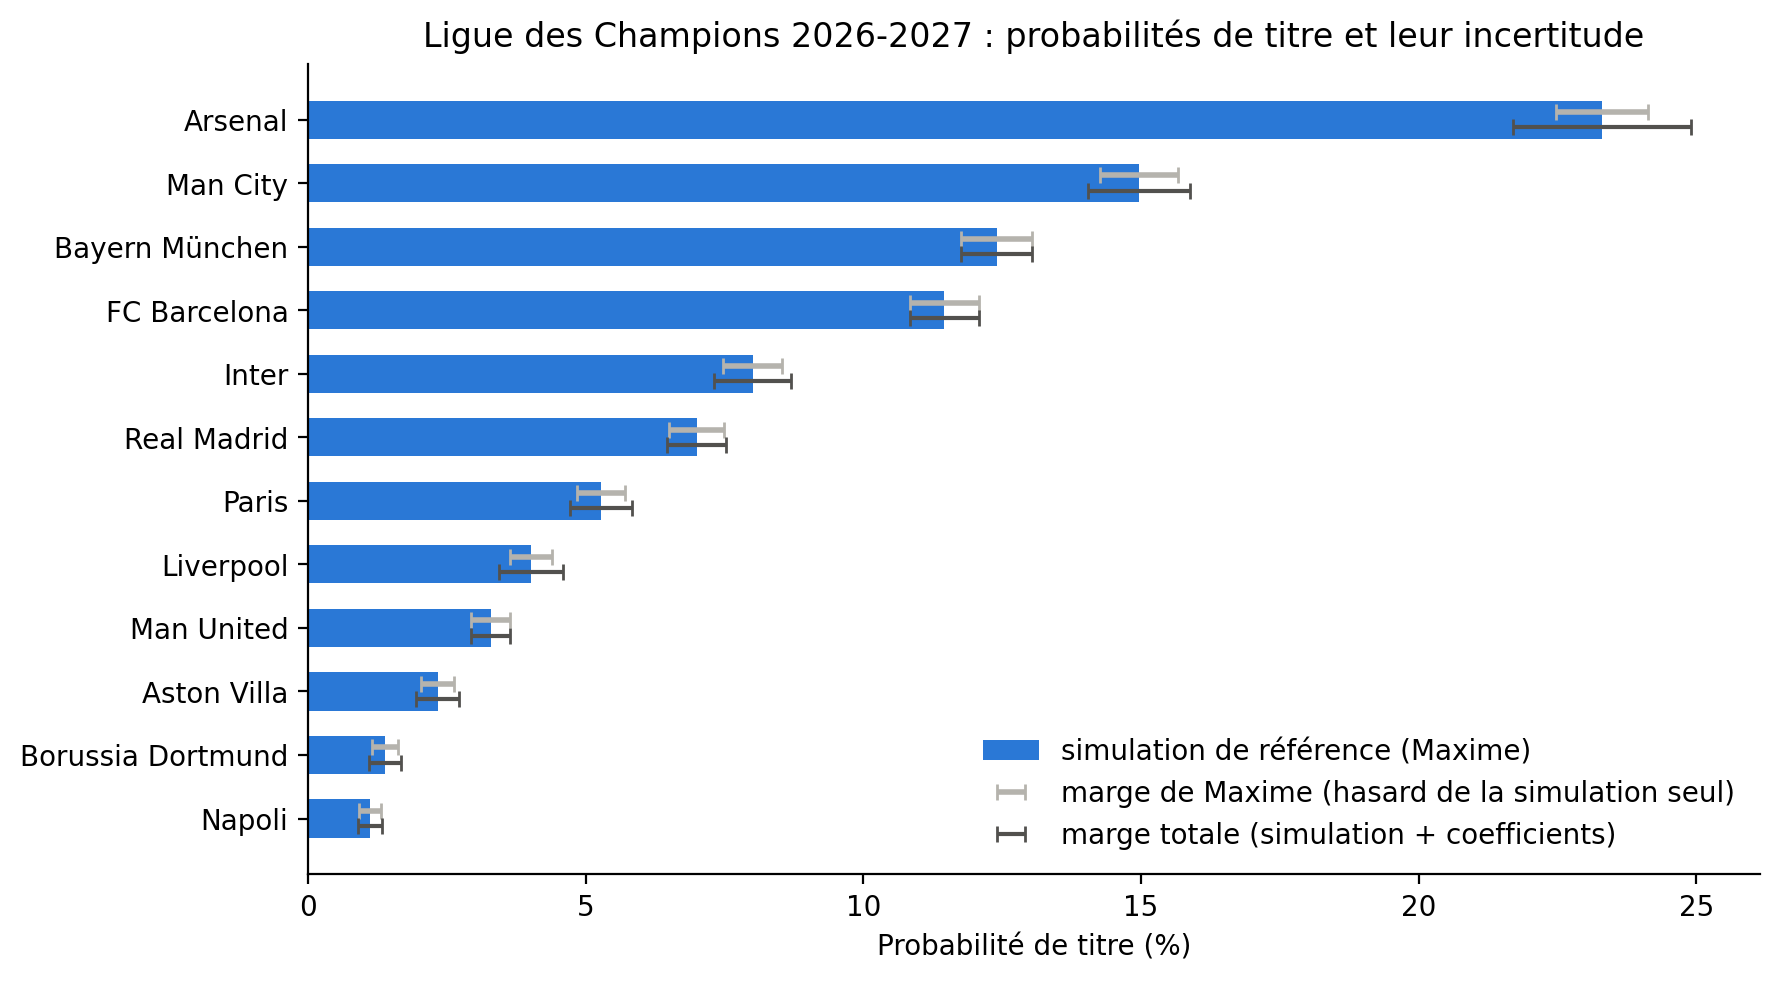

In [5]:
# Graphique : probabilité de titre des 12 favoris, avec la fourchette due au modèle
top = incertitude.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(top))
ax.barh(y, top['pct_titre_reference'], color=BLEU, height=0.6, label='simulation de référence (Maxime)')
ax.errorbar(top['pct_titre_reference'], y + 0.12, xerr=top['marge_titre_simulation_pts'], fmt='none', ecolor=GRIS,
            elinewidth=2, capsize=3, label='marge de Maxime (hasard de la simulation seul)')
ax.errorbar(top['pct_titre_reference'], y - 0.12, xerr=top['marge_titre_totale_pts'], fmt='none', ecolor=ENCRE,
            elinewidth=1.5, capsize=3, label='marge totale (simulation + coefficients)')
ax.set_yticks(y, top['nom_uefa'])
ax.set_xlabel('Probabilité de titre (%)')
ax.set_title('Ligue des Champions 2026-2027 : probabilités de titre et leur incertitude')
ax.legend(frameon=False, loc='lower right')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

**Lecture :**

| Club | Titre (Maxime) | Marge de Maxime | Marge due aux coefficients | **Marge totale** | **Fourchette à 95 %** |
|---|---|---|---|---|---|
| Arsenal | 23,30 % | ± 0,83 | ± 1,37 | **± 1,60** | **21,7 à 24,9 %** |
| Man City | 14,96 % | ± 0,70 | ± 0,60 | **± 0,92** | **14,0 à 15,9 %** |
| Bayern | 12,40 % | ± 0,65 | non détectable | **± 0,65** | **11,8 à 13,1 %** |
| Barcelone | 11,46 % | ± 0,62 | non détectable | **± 0,62** | **10,8 à 12,1 %** |
| Inter | 8,01 % | ± 0,53 | ± 0,45 | **± 0,70** | **7,3 à 8,7 %** |

- **Pour le favori, la vraie marge est presque deux fois plus grande** que celle annoncée : **± 1,6 point** au lieu de ± 0,8 pour Arsenal. C'est le club le plus sensible aux coefficients : sa probabilité dépend surtout de la force de l'avantage que donne l'Elo, puisque c'est lui qui a le plus haut Elo.
- **Pour les autres favoris, l'incertitude des coefficients est faible**, souvent du même ordre que le hasard de la simulation, voire trop petite pour être détectée (Bayern, Barcelone).
- **Pour atteindre les quarts, les coefficients pèsent plus que le hasard** : ± 2,2 points pour Arsenal (77,1 %), ± 2,6 pour Man City (66,5 %), contre environ ± 0,9 de hasard de simulation. L'incertitude du modèle domine.
- **Le classement des favoris ne change pas** : les fourchettes d'Arsenal (21,7-24,9 %) et de Man City (14,0-15,9 %) ne se touchent pas.
- **Ce que la marge ne couvre PAS :** elle ne tient compte que des coefficients. Les erreurs de l'Elo de départ, le fait que le modèle n'est pas démontré meilleur que le Dummy en élimination directe (`AUDIT_MODELE`), et les règles simplifiées s'y ajoutent. **La vraie incertitude est donc plus grande encore** : ces fourchettes sont un minimum.
- **Une précision de méthode :** avec 100 tirages, la part due aux coefficients n'est qu'un ordre de grandeur. « Non détectable » signifie qu'elle est plus petite que le bruit de nos blocs, pas qu'elle est nulle.

## 4. Analyse de sensibilité : terrain et poids de l'Elo

**La question :** les conclusions tiennent-elles si un coefficient est un peu différent ? On change **un seul coefficient à la fois** et on relance 10 000 saisons, **avec la même graine** pour chaque scénario : les différences viennent alors du coefficient changé, pas du hasard.

**Les scénarios, fixés avant de lancer :**
- **terrain** : bornes basse et haute de son intervalle de confiance, puis **aucun avantage du terrain** (cas extrême) ;
- **poids de l'Elo** : bornes de son intervalle de confiance, puis **−25 % et +25 %** (test de résistance, bien au-delà de l'intervalle) ;
- **nouveau format retiré** : l'audit a montré que son gain n'est pas démontré, on regarde donc ce qui change sans lui.

On regarde : le top 3 change-t-il ? Le classement des 36 clubs (corrélation de Spearman avec la référence) ? Et la probabilité de titre du favori ?

In [6]:
ic = dict(zip(COEFS, zip(ajust.conf_int()[0], ajust.conf_int()[1])))
scenarios = {
    'référence': {},
    'terrain : borne basse de l\'IC': {'coef_terrain': ic['coef_terrain'][0]},
    'terrain : borne haute de l\'IC': {'coef_terrain': ic['coef_terrain'][1]},
    'terrain : aucun avantage': {'coef_terrain': 0.0},
    'Elo : borne basse de l\'IC': {'coef_ecart_100': ic['coef_ecart_100'][0]},
    'Elo : borne haute de l\'IC': {'coef_ecart_100': ic['coef_ecart_100'][1]},
    'Elo : −25 % (stress)': {'coef_ecart_100': 0.75 * p['coef_ecart_100']},
    'Elo : +25 % (stress)': {'coef_ecart_100': 1.25 * p['coef_ecart_100']},
    'sans le nouveau format': {'coef_nouveau_format': 0.0},
}
debut = time.perf_counter()
# Même graine pour tous les scénarios : seules les différences de coefficient changent les résultats
sorties = Parallel(n_jobs=-1)(delayed(simuler_avec)(changement, N_SENSIBILITE, GRAINE) for changement in scenarios.values())
titres = pd.DataFrame({nom: 100 * s[0] for nom, s in zip(scenarios, sorties)}, index=clubs['nom_uefa'])
assert np.allclose(titres['référence'].to_numpy(), 100 * reference.set_index('nom_uefa').loc[titres.index, 'p_titre'].to_numpy())

ordre_ref = titres['référence'].sort_values(ascending=False).index
top3_ref = list(ordre_ref[:3])
sensibilite = pd.DataFrame({
    'top 3': [', '.join(titres[s].sort_values(ascending=False).index[:3]) for s in scenarios],
    'même top 3 (ordre compris)': [list(titres[s].sort_values(ascending=False).index[:3]) == top3_ref for s in scenarios],
    'même top 3 (ordre libre)': [set(titres[s].sort_values(ascending=False).index[:3]) == set(top3_ref) for s in scenarios],
    'Spearman avec la référence': [titres[s].corr(titres['référence'], method='spearman') for s in scenarios],
    f'titre {ordre_ref[0]} (%)': [titres.loc[ordre_ref[0], s] for s in scenarios],
    f'titre {ordre_ref[1]} (%)': [titres.loc[ordre_ref[1], s] for s in scenarios],
    f'titre {ordre_ref[2]} (%)': [titres.loc[ordre_ref[2], s] for s in scenarios],
}, index=list(scenarios))
print(f"{len(scenarios)} scénarios × {N_SENSIBILITE:,} saisons en {time.perf_counter() - debut:.0f} s\n")
print(sensibilite.round(3).to_string())

9 scénarios × 10,000 saisons en 91 s

                                                           top 3  même top 3 (ordre compris)  même top 3 (ordre libre)  Spearman avec la référence  titre Arsenal (%)  titre Man City (%)  titre Bayern München (%)
référence                      Arsenal, Man City, Bayern München                        True                      True                       1.000              23.30               14.96                     12.40
terrain : borne basse de l'IC  Arsenal, Man City, Bayern München                        True                      True                       0.984              22.73               15.23                     12.60
terrain : borne haute de l'IC  Arsenal, Man City, Bayern München                        True                      True                       0.995              23.12               14.36                     12.42
terrain : aucun avantage       Arsenal, Man City, Bayern München                        True                      

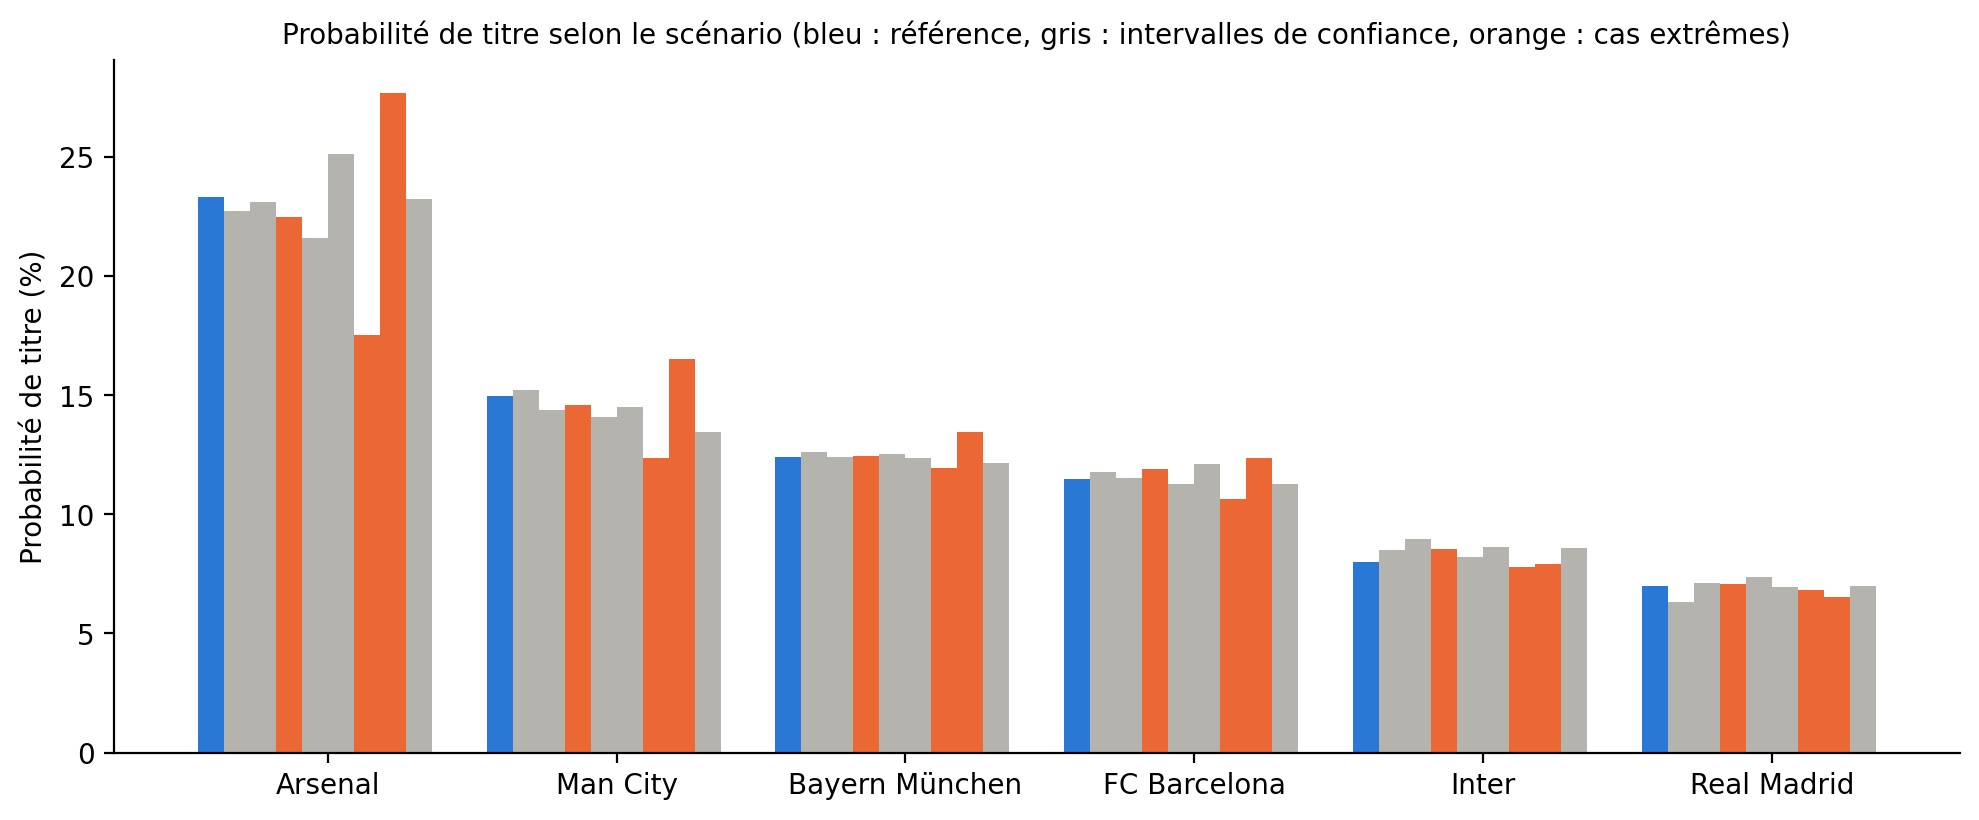

In [7]:
# Graphique : probabilité de titre des 6 favoris selon le scénario
favoris = list(ordre_ref[:6])
fig, ax = plt.subplots(figsize=(10, 4.2))
largeur = 0.09
for i, s in enumerate(scenarios):
    couleur = BLEU if s == 'référence' else (ORANGE if 'stress' in s or 'aucun' in s else GRIS)
    ax.bar(np.arange(len(favoris)) + (i - len(scenarios) / 2) * largeur, titres.loc[favoris, s], largeur, color=couleur)
ax.set_xticks(np.arange(len(favoris)), favoris)
ax.set_ylabel('Probabilité de titre (%)')
ax.set_title('Probabilité de titre selon le scénario (bleu : référence, gris : intervalles de confiance, orange : cas extrêmes)', fontsize=10)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

**Lecture :**

| Scénario | Top 3 | Spearman | Arsenal | Man City | Bayern |
|---|---|---|---|---|---|
| **Référence** | Arsenal, City, Bayern | 1,000 | 23,3 % | 15,0 % | 12,4 % |
| Terrain : bornes de l'IC | identique | 0,984 à 0,995 | 22,7 à 23,1 % | 14,4 à 15,2 % | 12,4 à 12,6 % |
| Terrain : aucun avantage | identique | 0,990 | 22,5 % | 14,6 % | 12,4 % |
| Elo : bornes de l'IC | identique | 0,990 à 0,992 | **21,6 à 25,1 %** | 14,1 à 14,5 % | 12,4 à 12,5 % |
| Elo : −25 % / +25 % (stress) | identique | 0,992 à 0,995 | **17,5 à 27,7 %** | 12,4 à 16,5 % | 12,0 à 13,5 % |
| Sans le nouveau format | identique | 0,985 | 23,2 % | 13,5 % | 12,2 % |

- **Le top 3 ne bouge dans aucun des 9 scénarios**, ni dans sa composition, ni dans son ordre : Arsenal, puis Man City, puis Bayern. Le classement des 36 clubs reste presque identique (Spearman toujours ≥ 0,984).
- **Le terrain compte très peu pour le titre** : même sans aucun avantage du terrain, Arsenal ne perd que 0,8 point (22,5 %). C'est logique : en phase de ligue, chaque club joue 4 matchs à domicile et 4 à l'extérieur, donc l'avantage s'équilibre.
- **Le poids de l'Elo est le réglage qui compte** : dans son seul intervalle de confiance, la probabilité d'Arsenal va de 21,6 à 25,1 %. Plus l'Elo pèse, plus les favoris sont favoris. Au test de résistance (± 25 %), elle va de 17,5 à 27,7 %, mais Arsenal reste devant.
- **Retirer le nouveau format change peu** : Arsenal 23,2 %, Man City 13,5 % (−1,5 point). L'audit n'avait pas démontré son gain : on voit ici qu'il ne change pas non plus les conclusions.

## 5. Export

Deux fichiers dans `output/` (non versionnés, comme les autres sorties) :
- `incertitude_titre_2026.csv` : pour chaque club, la probabilité de titre de référence, sa fourchette à 95 % quand les coefficients sont incertains, et la même chose pour les quarts de finale ;
- `sensibilite_2026.csv` : la probabilité de titre de chaque club dans chacun des 9 scénarios.

In [8]:
assert len(incertitude) == 36 and incertitude['club_id'].is_unique
assert (incertitude['pct_titre_ic95_bas'] <= incertitude['pct_titre_ic95_haut']).all()
assert np.isclose(incertitude['pct_titre_moyen_coefs_incertains'].sum(), 100) and np.isclose(incertitude['pct_titre_reference'].sum(), 100)
assert np.allclose(titres.sum(), 100)

incertitude.to_csv('../output/incertitude_titre_2026.csv', index=False, encoding='utf-8-sig')
titres.reset_index().rename(columns={'nom_uefa': 'club'}).to_csv('../output/sensibilite_2026.csv', index=False, encoding='utf-8-sig')
print("Fichiers créés : output/incertitude_titre_2026.csv (36 lignes), output/sensibilite_2026.csv (36 lignes × 9 scénarios)")

Fichiers créés : output/incertitude_titre_2026.csv (36 lignes), output/sensibilite_2026.csv (36 lignes × 9 scénarios)


**Lecture :** les deux fichiers sont créés, 36 lignes chacun, avec des probabilités qui somment bien à 100 % dans chaque scénario.

## 6. Conclusion

**Ce que ce notebook apporte :**
1. **Des intervalles honnêtes.** La marge de ± 0,8 point annoncée pour Arsenal ne mesurait que le hasard de la simulation. En ajoutant l'incertitude des coefficients, elle passe à **± 1,6 point** : **21,7 à 24,9 %** de chances de titre. Pour atteindre les quarts, l'incertitude du modèle est même **2 à 3 fois plus grande** que le hasard de la simulation pour les trois favoris.
2. **Un classement robuste.** Le top 3 (Arsenal, Man City, Bayern) ne change dans **aucun** des 9 scénarios testés, y compris les cas extrêmes.
3. **Ce qui compte vraiment : le poids de l'Elo.** C'est lui qui fait varier les probabilités, pas l'avantage du terrain ni le nouveau format.

**Ce qu'on peut dire en soutenance :** « Arsenal est le favori, avec environ 22 à 25 % de chances de titre, et ce classement résiste à tous nos tests de sensibilité. Mais ces fourchettes ne couvrent que l'incertitude des coefficients : l'Elo de départ et les limites du modèle en élimination directe ajoutent une incertitude qu'on ne sait pas chiffrer. »

**Limites :**
- **L'incertitude de l'Elo de départ n'est pas prise en compte** : les 36 Elo sont traités comme exacts. Pour les clubs à Elo estimé, l'erreur moyenne est d'environ 43 points (`v2_elo`).
- **Le moteur est celui de Maxime**, avec ses règles simplifiées (départage final au hasard, retour chez le meilleur rang). On ne les a pas testées ici.
- **100 tirages de coefficients** suffisent pour un ordre de grandeur des marges, pas pour un chiffre précis au dixième de point.